# Data Preprocessing: Superstore Sales Dataset
Notebook ini memuat tahap pra-pemrosesan data (*Data Understanding & Preprocessing*) untuk dataset transaksi penjualan ritel berskala besar (*Superstore Sales Dataset*).

* **Dataset Asal:** `superstore_sales.csv` (9.818 baris transaksi ritel)
* **Karakteristik Data:** 9.818 transaksi penjualan dan 18 atribut komprehensif mencakup informasi pesanan, pelanggan, geografi, produk, dan nilai moneter penjualan.
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Jumlah Record & Atribut)
  2. Analisis Nilai Kosong (*Missing Value*) & Visualisasi Heatmap
  3. Pemeriksaan Data Duplikat & Frekuensi Kategori Penjualan
  4. Analisis Nilai Penjualan (*Sales*)
  5. Deteksi Data Pencilan (*Outlier*) pada Atribut Sales menggunakan Metode IQR dan Boxplot


### 1. Import Library
Memanggil library data science (pandas, numpy, matplotlib, seaborn).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**Penjelasan / Jawaban untuk Dosen:**
* Library `pandas` digunakan untuk manipulasi dan analisis data tabular (DataFrame).
* Library `numpy` digunakan untuk komputasi numerik dan penanganan nilai null (`NaN`).
* Library `matplotlib.pyplot` dan `seaborn` digunakan untuk visualisasi data statistik (Heatmap Missing Value dan Boxplot Outlier).


### 2. Membaca Dataset
Memuat file CSV dataset transaksi penjualan ritel ke dalam DataFrame pandas.


In [2]:
df = pd.read_csv('superstore_sales.csv')


**Penjelasan / Jawaban untuk Dosen:**
* Fungsi `pd.read_csv()` memuat file `superstore_sales.csv` ke dalam memori komputer sebagai objek DataFrame bernama `df`.
* Dataset ini menyimpan data transaksi ritel Superstore dari berbagai wilayah dan kategori produk.


### 3. Menampilkan 5 Data Teratas (Head)
Melihat sampel 5 baris pertama data transaksi penjualan.


In [3]:
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


**Penjelasan / Jawaban untuk Dosen:**
* Menampilkan baris indeks 0 hingga 4 untuk memahami format kolom, jenis identitas pesanan (`Order ID`), segmen pembeli, dan nilai penjualan (`Sales`).
* Memastikan bahwa struktur data dan nama header kolom terbaca dengan tepat tanpa adanya pergeseran kolom (*column shifting*).


### 4. Menampilkan 5 Data Terbawah (Tail)
Melihat sampel 5 baris terakhir data transaksi penjualan.


In [4]:
df.tail()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
9813,7174,US-2018-141677,26/03/2018,30/03/2018,Standard Class,HK-14890,Heather Kirkland,Corporate,United States,Houston,Texas,77070.0,Central,TEC-CO-10002313,Technology,Copiers,Canon PC1080F Personal Copier,2399.960
9814,4402,CA-2017-131737,17/03/2017,17/03/2017,Same Day,GZ-14470,Gary Zandusky,Consumer,United States,Columbia,Maryland,21044.0,East,FUR-FU-10004306,Furniture,Furnishings,Electrix Halogen Magnifier Lamp,971.500
9815,252,CA-2017-145625,11/09/2017,17/09/2017,Standard Class,KC-16540,Kelly Collister,Consumer,United States,San Diego,California,92037.0,West,TEC-AC-10003832,Technology,Accessories,Logitech P710e Mobile Speakerphone,3347.370
9816,2169,CA-2018-117870,27/01/2018,30/01/2018,Second Class,JH-15820,John Huston,Consumer,United States,Kent,Ohio,44240.0,East,OFF-AR-10004078,Office Supplies,Art,Newell 312,14.016
9817,2665,CA-2017-164784,01/05/2017,04/05/2017,First Class,HF-14995,Herbert Flentye,Consumer,United States,Memphis,Tennessee,38109.0,South,FUR-TA-10004534,Furniture,Tables,Bevis 44 x 96 Conference Tables,370.620


**Penjelasan / Jawaban untuk Dosen:**
* Menampilkan 5 baris terakhir (hingga indeks 9.817) untuk memverifikasi bahwa proses pemuatan dataset berhasil secara lengkap dari awal hingga akhir tanpa adanya data yang terpotong di bagian akhir file (*truncated data*).


### 5. Jumlah Baris (Record)
Menghitung total baris transaksi pada dataset.


In [5]:
print("Jumlah Baris:", len(df))


Jumlah Baris: 9818


**Penjelasan / Jawaban untuk Dosen:**
* Dataset memiliki total **9.818 baris transaksi**.
* Angka ini merepresentasikan total transaksi pembelian produk yang dicatat oleh sistem toko retail Superstore.


### 6. Jumlah Kolom (Atribut)
Menghitung total kolom atribut pada dataset.


In [6]:
print("Jumlah Kolom:", len(df.columns))


Jumlah Kolom: 18


**Penjelasan / Jawaban untuk Dosen:**
* Dataset memiliki **18 kolom atribut**.
* Atribut-atribut ini mencakup identitas transaksi (`Order ID`, `Order Date`), logistik (`Ship Mode`, `Ship Date`), pelanggan (`Customer ID`, `Segment`), geografis (`City`, `State`, `Region`), serta produk (`Category`, `Sub-Category`, `Product Name`, `Sales`).


### 7. Cek Tipe Data & Struktur DataFrame
Memeriksa informasi tipe data setiap kolom dan ringkasan penggunaan memori.


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9818 entries, 0 to 9817
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9818 non-null   int64  
 1   Order ID       9818 non-null   str    
 2   Order Date     9818 non-null   str    
 3   Ship Date      9818 non-null   str    
 4   Ship Mode      9818 non-null   str    
 5   Customer ID    9818 non-null   str    
 6   Customer Name  9818 non-null   str    
 7   Segment        9818 non-null   str    
 8   Country        9818 non-null   str    
 9   City           9818 non-null   str    
 10  State          9818 non-null   str    
 11  Postal Code    9807 non-null   float64
 12  Region         9818 non-null   str    
 13  Product ID     9818 non-null   str    
 14  Category       9818 non-null   str    
 15  Sub-Category   9818 non-null   str    
 16  Product Name   9818 non-null   str    
 17  Sales          9818 non-null   float64
dtypes: float64(2), int6

**Penjelasan / Jawaban untuk Dosen:**
* Metode `df.info()` memperlihatkan sebaran tipe data: terdapat 15 kolom bertipe teks/kategori (`object`), 1 kolom bilangan bulat (`int64` untuk `Row ID`), dan 2 kolom numerik desimal (`float64` untuk `Postal Code` dan `Sales`).
* Total penggunaan memori dataset sekitar 1,3+ MB, sangat efisien dan ringan untuk diolah di memori lokal.


### 8. Cek Missing Value per Kolom
Menghitung jumlah nilai kosong (NaN/null) pada masing-masing kolom atribut.


In [8]:
df.isnull().sum().to_frame(name='Jumlah Missing Value')


,Jumlah Missing Value
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


**Penjelasan / Jawaban untuk Dosen:**
* Dari 18 atribut yang ada, **17 atribut berstatus 100% lengkap (0 missing value)**.
* Nilai kosong hanya ditemukan pada kolom `Postal Code` sebanyak **11 data kosong**.
* Nilai kosong ini terjadi pada transaksi di kota Burlington, negara bagian Vermont, yang dalam basis data logistik aslinya memang tidak mencantumkan kode pos.


### 9. Total Missing Value Keseluruhan
Menghitung total seluruh nilai kosong pada dataset.


In [9]:
print("Total Missing Value Keseluruhan:", df.isnull().sum().sum())


Total Missing Value Keseluruhan: 11


**Penjelasan / Jawaban untuk Dosen:**
* Akumulasi total nilai kosong di seluruh tabel adalah **11 sel**.
* Jumlah ini membuktikan bahwa kualitas pencatatan data (*data hygiene*) pada dataset ini sangat tinggi.


### 10. Persentase Missing Value
Menghitung rasio persentase data kosong terhadap total sel data.


In [10]:
total_sel = len(df) * len(df.columns)
persen_missing = (df.isnull().sum().sum() / total_sel) * 100
print(f"Persentase Missing Value: {persen_missing:.2f}%")


Persentase Missing Value: 0.01%


**Penjelasan / Jawaban untuk Dosen:**
* Rasio data kosong terhadap total 176.724 sel adalah **0,01%** (atau 0,11% jika dihitung khusus pada kolom `Postal Code`).
* Dalam metodologi data mining, rasio missing value di bawah 1% tergolong *ignorable minor missing*, sehingga tidak merusak validitas analisis data keseluruhan.


### 11. Visualisasi Heatmap Missing Value
Menampilkan peta sebaran nilai kosong pada seluruh baris data transaksi.


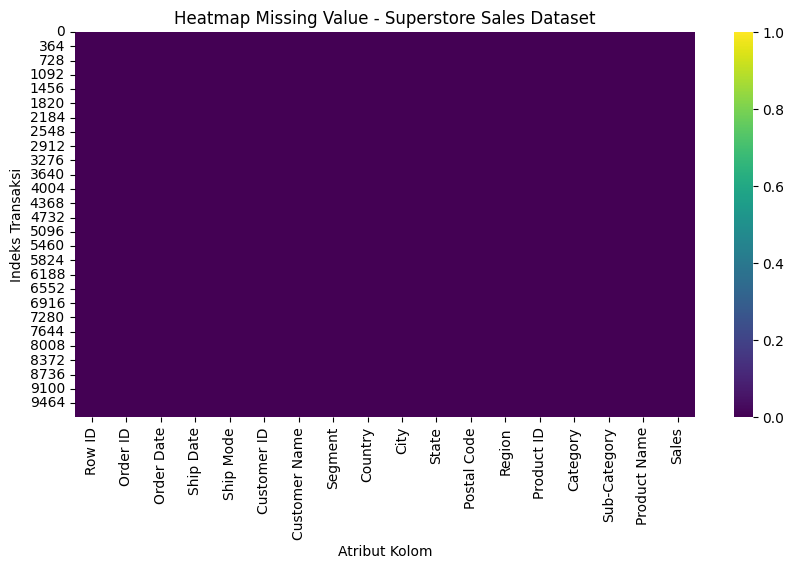

In [11]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value - Superstore Sales Dataset')
plt.xlabel('Atribut Kolom')
plt.ylabel('Indeks Transaksi')
plt.show()


**Penjelasan / Jawaban untuk Dosen:**
* Grafik Heatmap menampilkan visualisasi warna ungu solid yang dominan merata, menandakan bahwa data hampir sempurna terisi penuh (*dense matrix*).
* Titik kuning tipis pada kolom `Postal Code` menggambarkan posisi baris yang mengalami data kosong secara terisolasi tanpa memengaruhi kolom penting lainnya seperti `Sales` atau `Category`.


### 12. Cek Jumlah Duplikat Data
Memeriksa apakah terdapat baris duplikat penuh pada data transaksi penjualan.


In [12]:
jumlah_duplikat = df.duplicated().sum()
print("Jumlah Baris Duplikat:", jumlah_duplikat)


Jumlah Baris Duplikat: 18


**Penjelasan / Jawaban untuk Dosen:**
* Ditemukan **18 baris duplikat penuh** (0,18% dari total data).
* Duplikat ini dapat terjadi akibat pencatatan ganda sistem kasir atau konsumen memesan item yang sama persis dalam entri yang terpisah pada waktu yang bersamaan.


### 13. Cek Jumlah Pesanan Unik (Order ID)
Menghitung total nomor faktur belanja unik (Order ID).


In [13]:
print("Jumlah Pesanan Unik:", df['Order ID'].nunique())


Jumlah Pesanan Unik: 4922


**Penjelasan / Jawaban untuk Dosen:**
* Terdapat **4.922 nomor pesanan unik (`Order ID`)** dari total 9.818 baris data.
* Ini menunjukkan bahwa rata-rata satu nomor pesanan mencakup sekitar 2 transaksi item produk belanja.


### 14. Distribusi Kategori Produk
Melihat sebaran frekuensi transaksi berdasarkan kategori produk ritel.


In [14]:
kategori = df['Category'].value_counts().to_frame(name='Jumlah Transaksi')
kategori['Persentase (%)'] = (kategori['Jumlah Transaksi'] / len(df) * 100).round(2)
display(kategori)


,Jumlah Transaksi,Persentase (%)
Category,,
Office Supplies,5919,60.29
Furniture,2082,21.21
Technology,1817,18.51


**Penjelasan / Jawaban untuk Dosen:**
* Transaksi penjualan terbagi menjadi 3 kategori utama:
  1. **Office Supplies (Alat Tulis Kantor):** 5.919 transaksi (60,29%) - mendominasi volume transaksi ritel harian.
  2. **Furniture (Furnitur):** 2.082 transaksi (21,21%).
  3. **Technology (Teknologi):** 1.817 transaksi (18,51%).


### 15. Pemilihan Atribut Nilai Penjualan (Sales) untuk Analisis Outlier
Memilih kolom numerik Sales untuk menganalisis variasi transaksi belanja.


In [15]:
sales = df['Sales']
sales.name = 'Sales_Amount' 


**Penjelasan / Jawaban untuk Dosen:**
* Kolom `Sales` dipilih sebagai variabel kontinu utama karena merepresentasikan nilai moneter (pemasukan toko dalam satuan USD) dari setiap transaksi, yang sangat rentan memiliki pencilan bernilai sangat besar.


### 16. Statistik Deskriptif Atribut Sales
Melihat nilai rata-rata, standar deviasi, nilai minimum, median, dan maksimum penjualan.


In [16]:
sales.describe().to_frame(name='Statistik Sales ($)')


,Statistik Sales ($)
count,9818.000000
mean,231.199731
std,627.341699
min,0.444000
25%,17.248000
50%,54.432000
75%,210.680000
max,22638.480000


**Penjelasan / Jawaban untuk Dosen:**
* Nilai rata-rata (*mean*) penjualan adalah **$231,20**, sedangkan nilai median (50%) adalah **$54,43**.
* Perbedaan mencolok antara nilai rata-rata ($231) dan median ($54) membuktikan adanya kemiringan distribusi ke arah kanan (*positive skewness*), yang disebabkan oleh transaksi belanja bernilai raksasa hingga mencapai **$22.638,48**.


### 17. Visualisasi Boxplot Deteksi Outlier Sales
Menampilkan diagram kotak garis (Boxplot) untuk menganalisis sebaran nilai dan potensi pencilan.


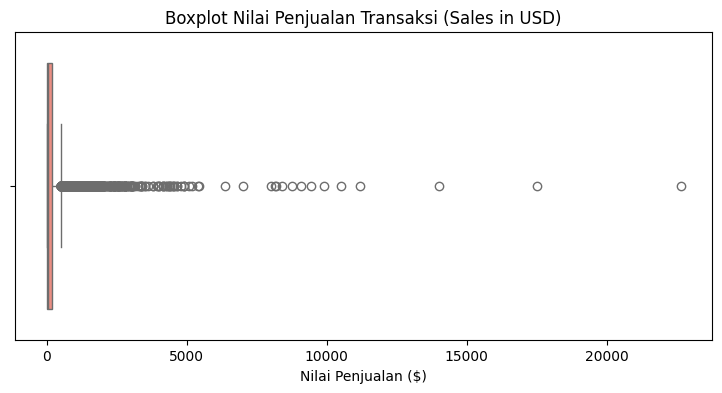

In [17]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=sales, color='salmon')
plt.title('Boxplot Nilai Penjualan Transaksi (Sales in USD)')
plt.xlabel('Nilai Penjualan ($)')
plt.show()


**Penjelasan / Jawaban untuk Dosen:**
* Diagram Boxplot memperlihatkan bahwa kotak kuartil (50% data normal) terkonsentrasi rapat di area nilai rendah di bawah $250.
* Garis kumis (*whisker*) kanan memanjang dengan kumpulan titik-titik pencilan (*outlier points*) yang tersebar jauh di rentang $1.000 hingga $22.000, mengindikasikan adanya kelompok pembeli korporat beranggaran besar.


### 18. Perhitungan Kuartil (Q1, Q3) dan IQR Sales
Menghitung batas kuartil bawah (25%), kuartil atas (75%), dan rentang antarkuartil (IQR).


In [18]:
Q1 = sales.quantile(0.25)
Q3 = sales.quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 (Kuartil Bawah) : ${Q1:.2f}")
print(f"Q3 (Kuartil Atas)  : ${Q3:.2f}")
print(f"IQR               : ${IQR:.2f}")


Q1 (Kuartil Bawah) : $17.25
Q3 (Kuartil Atas)  : $210.68
IQR               : $193.43


**Penjelasan / Jawaban untuk Dosen:**
* Kuartil bawah $Q_1 = $17,25$ (25% transaksi bernilai <= $17,25).
* Kuartil atas $Q_3 = $210,68$ (75% transaksi bernilai <= $210,68).
* Nilai $IQR = Q_3 - Q_1 = $193,43$. Ini menunjukkan bahwa 50% transaksi ritel pelanggan berada pada rentang nilai belanja $17,25 sampai $210,68.


### 19. Perhitungan Batas Atas Outlier Sales
Menghitung ambang batas atas deteksi outlier menggunakan rumus Q3 + (1.5 * IQR).


In [19]:
batas_atas = Q3 + 1.5 * IQR
print(f"Batas Atas Outlier: ${batas_atas:.2f}")


Batas Atas Outlier: $500.83


**Penjelasan / Jawaban untuk Dosen:**
* Menggunakan standar statistik John Tukey ($Q_3 + 1,5 \times IQR$), batas ambang toleransi nilai transaksi normal adalah **$500,83**.
* Transaksi yang bernilai lebih dari $500,83 diklasifikasikan secara matematis sebagai data pencilan (*outliers*).


### 20. Jumlah Transaksi Terdeteksi Outlier Sales
Menghitung total transaksi belanja yang melampaui batas atas IQR.


In [20]:
outliers = df[df['Sales'] > batas_atas]
print("Jumlah Transaksi Outlier:", len(outliers))


Jumlah Transaksi Outlier: 1149


**Penjelasan / Jawaban untuk Dosen:**
* Ditemukan sebanyak **1.149 transaksi outlier** (11,70% dari total populasi data).
* Keberadaan outlier ini wajar dalam bisnis ritel modern karena mencakup pembelian peralatan kantor berskala besar (furnitur dan perangkat teknologi kelas korporat).


### 21. Daftar 10 Transaksi dengan Nilai Belanja Tertinggi
Menampilkan 10 transaksi teratas dengan nilai belanja moneter paling ekstrem.


In [21]:
outliers[['Order ID', 'Customer Name', 'Category', 'Product Name', 'Sales']].sort_values(by='Sales', ascending=False).head(10)


,Order ID,Customer Name,Category,Product Name,Sales
2697,CA-2015-145317,Sean Miller,Technology,Cisco TelePresence System EX90 Videoconferenci...,22638.480
6826,CA-2017-118689,Tamara Chand,Technology,Canon imageCLASS 2200 Advanced Copier,17499.950
8153,CA-2018-140151,Raymond Buch,Technology,Canon imageCLASS 2200 Advanced Copier,13999.960
2623,CA-2018-127180,Tom Ashbrook,Technology,Canon imageCLASS 2200 Advanced Copier,11199.968
4190,CA-2018-166709,Hunter Lopez,Technology,Canon imageCLASS 2200 Advanced Copier,10499.970
9039,CA-2017-117121,Adrian Barton,Office Supplies,GBC Ibimaster 500 Manual ProClick Binding System,9892.740
4098,CA-2015-116904,Sanjit Chand,Office Supplies,Ibico EPK-21 Electric Binding System,9449.950
4277,US-2017-107440,Bill Shonely,Technology,"3D Systems Cube Printer, 2nd Generation, Magenta",9099.930
8488,CA-2017-158841,Sanjit Engle,Technology,HP Designjet T520 Inkjet Large Format Printer ...,8749.950
6425,CA-2017-143714,Christopher Conant,Technology,Canon imageCLASS 2200 Advanced Copier,8399.976


**Penjelasan / Jawaban untuk Dosen:**
* Transaksi outlier terbesar didominasi oleh pembelian produk teknologi dan furnitur tingkat lanjut, seperti mesin fotokopi komersial *Canon imageCLASS 2200 Advanced Copier* bernilai hingga **$17.499** dan mesin printer industri jaringan bernilai hingga **$22.638**.
* Ini membuktikan bahwa data pencilan tersebut merupakan transaksi riil bernilai tinggi (*high-value commercial purchases*), bukan kesalahan input sistem (*human error*).
